In [14]:
!pip install -q kagglehub



In [15]:
import kagglehub
import os
import cv2
import matplotlib.pyplot as plt

path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Dataset path:", path)



Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset path: /kaggle/input/neu-surface-defect-database


In [21]:
# Reduce image noise
blur = cv2.GaussianBlur(
    image,
    (5, 5),
    0
)

# Detect edges
edges = cv2.Canny(
    blur,
    50,
    150
)

# Connect broken edges
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (3, 3)
)

morph = cv2.morphologyEx(
    edges,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=2
)

# Find connected regions
contours, _ = cv2.findContours(
    morph,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Draw detected regions
result = cv2.cvtColor(
    image,
    cv2.COLOR_GRAY2BGR
)

for contour in contours:

    area = cv2.contourArea(contour)

    if area > 5:

        x, y, w, h = cv2.boundingRect(
            contour
        )

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            1
        )

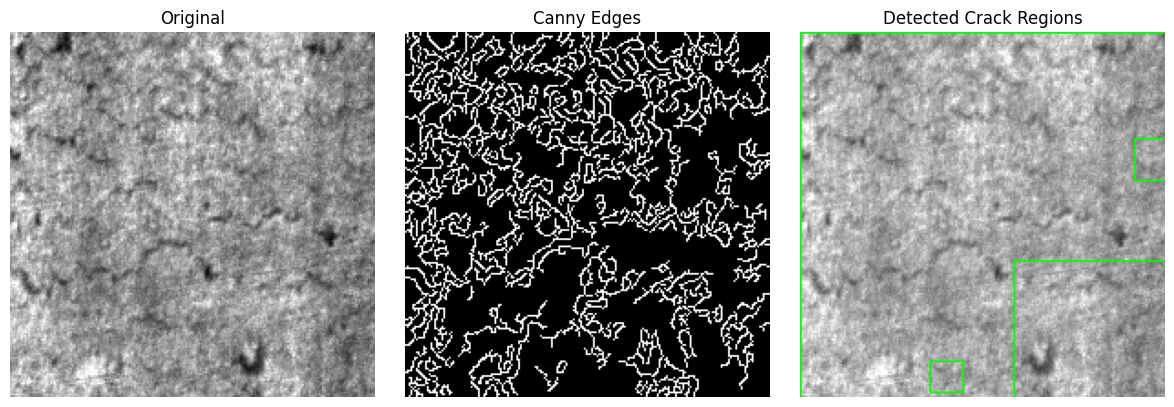

In [22]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
)
plt.title("Detected Crack Regions")
plt.axis("off")

plt.tight_layout()
plt.show()